<a href="https://colab.research.google.com/github/denizsecmen/AOEII-AI-Prediction/blob/main/Main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
#Importing Libaries
import sys
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing  import StandardScaler,MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [13]:
#Retrieve main data
data=pd.read_csv("/content/drive/MyDrive/AOEII-data/rankedrm.csv",encoding="latin-1")
data=pd.DataFrame(data)
data.dropna(subset=[column for column in data.columns if data[column].dtype==int or  data[column].dtype==float],inplace=True)
print(data.columns)

Index(['match_uuid', 'started', 'finished', 'map_type', 'steam_id.win',
       'name.win', 'country.win', 'rating.win', 'rating_change.win', 'civ.win',
       'color.win', 'steam_id.lose', 'name.lose', 'country.lose',
       'rating.lose', 'rating_change.lose', 'civ.lose', 'color.lose',
       'map_type.name', 'civ.lose.name', 'civ.win.name', 'matchup',
       'duration'],
      dtype='object')


In [14]:
#Displaying main info about data
played_maps = data.groupby("map_type").size().reset_index(name="played_games_count")
civ_winner = data.groupby("civ.win").size().reset_index(name="civilisation_name_count")
rating_diff= data[["rating.win","rating.lose"]].apply(lambda x:x["rating.win"]-x["rating.lose"],axis=1)
rating_diff=pd.DataFrame(rating_diff[np.isnan(rating_diff)==False],columns=["Difference"])
rating_diff = ((rating_diff["Difference"] // 100 * 100).value_counts().sort_index()).reset_index(name="difference_count")
print("Rating difference")
print(rating_diff)
print("\n")
print("Player maps per game")
print(played_maps)
print("\n")
print("Civilisation per game")
print(civ_winner)

Rating difference
    Difference  difference_count
0       -500.0                 3
1       -400.0                 3
2       -300.0                25
3       -200.0               255
4       -100.0             23200
5          0.0             28685
6        100.0               559
7        200.0                65
8        300.0                21
9        400.0                11
10       500.0                 8
11       600.0                 6
12       700.0                 2
13      1000.0                 1


Player maps per game
    map_type  played_games_count
0          9               34179
1         16                1649
2         19                 944
3         21                 297
4         29                5595
5         33                1035
6         67                1628
7         71                 929
8         72                1050
9         77                 907
10       140                3114
11       150                1517


Civilisation per game
    civ.win

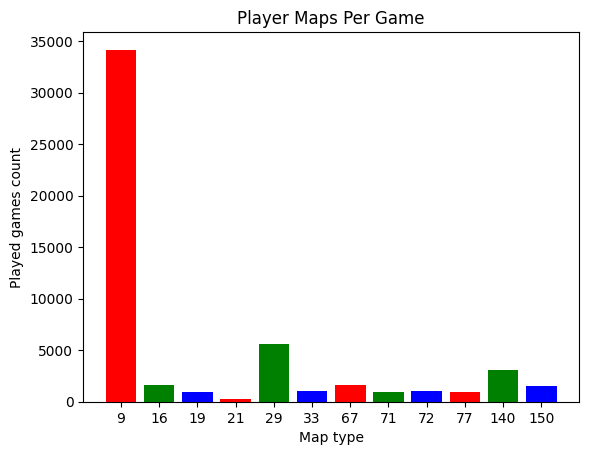

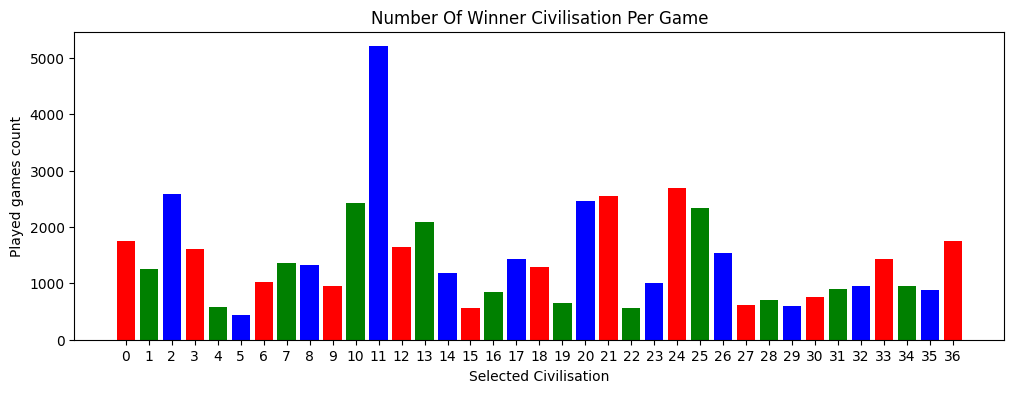

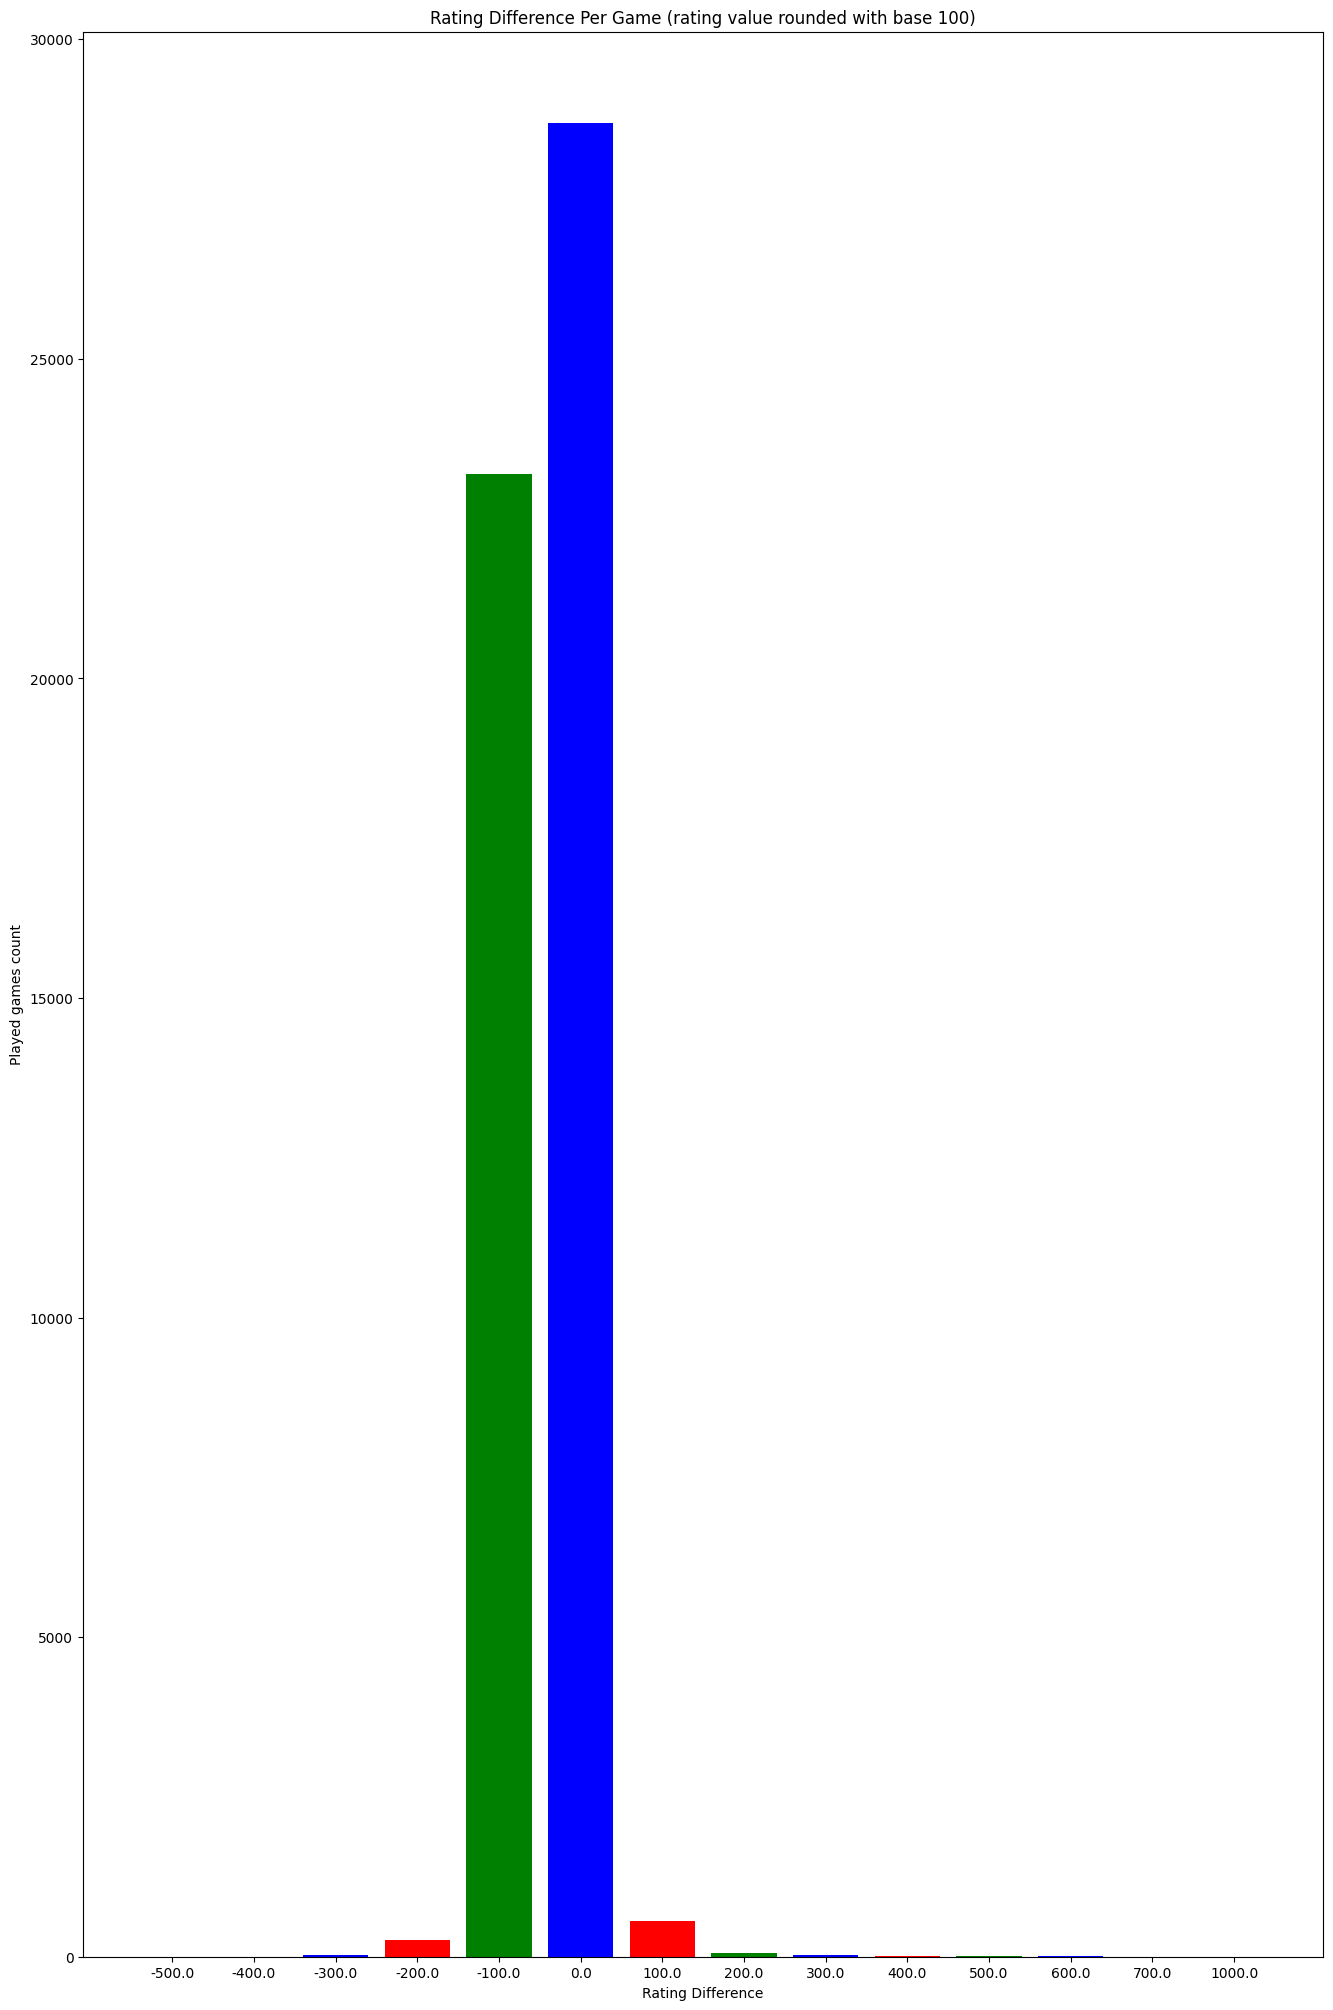

In [15]:
#Displaying main info about data with bar graph
plt.bar(x=played_maps["map_type"].astype(str),height=played_maps["played_games_count"],color=["red","green","blue",])
plt.title("Player Maps Per Game")
plt.xlabel("Map type")
plt.ylabel("Played games count")
plt.show()
plt.figure(figsize=(12,4))
plt.bar(x=civ_winner["civ.win"].astype(str),height=civ_winner["civilisation_name_count"],color=["red","green","blue",])
plt.title("Number Of Winner Civilisation Per Game")
plt.xlabel("Selected Civilisation")
plt.ylabel("Played games count")
plt.show()
plt.figure(figsize=(16,25))
plt.bar(x=rating_diff["Difference"].astype(str),height=rating_diff["difference_count"],color=["red","green","blue",])
plt.title("Rating Difference Per Game (rating value rounded with base 100)")
plt.xlabel("Rating Difference")
plt.ylabel("Played games count")
plt.show()

In [16]:
#Prerocessing
str_columns=[column for column in data.columns if (data[column].dtype!=int and  data[column].dtype!=float) or column.startswith("steam_id") or column.startswith("rating_change")]
data.drop([*str_columns],axis=1,inplace=True)
sc=StandardScaler()
sc.fit(data)
scaled_data=sc.transform(data)
normalised_data=MinMaxScaler()
normalised_data.fit(data)
normalised_data=normalised_data.transform(data)
preprocessed_data=pd.DataFrame(normalised_data,columns=data.columns)
print(preprocessed_data)

       map_type  rating.win   civ.win  color.win  rating.lose  civ.lose  \
0      0.000000    0.501199  0.527778      0.500     0.497569  0.055556   
1      0.000000    0.433253  0.000000      0.250     0.417747  0.000000   
2      0.000000    0.440847  0.305556      0.250     0.427066  0.138889   
3      0.929078    0.493605  0.305556      0.250     0.490276  0.555556   
4      0.141844    0.394484  0.083333      0.750     0.384522  0.194444   
...         ...         ...       ...        ...          ...       ...   
52839  0.439716    0.371703  0.305556      0.625     0.365478  0.555556   
52840  0.000000    0.535572  0.750000      0.125     0.525932  0.777778   
52841  0.482270    0.377298  0.000000      0.125     0.354943  0.222222   
52842  0.439716    0.322542  0.722222      0.375     0.307536  0.583333   
52843  0.000000    0.365308  0.416667      0.125     0.347245  0.333333   

       color.lose  
0        0.000000  
1        0.571429  
2        0.000000  
3        0.285714  

In [17]:
#Creation of win-lose column
length = data.shape[0] // 2
preprocessed_data = preprocessed_data.reset_index(drop=True)

preprocessed_data.rename(columns={
    "rating.win": "player1_rating",
    "rating.lose": "player2_rating",
    "civ.win": "player1_civ",
    "civ.lose": "player2_civ"
}, inplace=True)
preprocessed_data["win"] = 1
swap = preprocessed_data.index >= length
preprocessed_data.loc[swap, ["player1_rating", "player2_rating"]] = preprocessed_data.loc[swap, ["player2_rating", "player1_rating"]].values
preprocessed_data.loc[swap, ["player1_civ", "player2_civ"]] = preprocessed_data.loc[swap, ["player2_civ", "player1_civ"]].values
preprocessed_data.loc[swap, "win"] = 0
preprocessed_data=preprocessed_data.sample(frac=1)
print(preprocessed_data)

       map_type  player1_rating  player1_civ  color.win  player2_rating  \
32313  0.000000        0.306726     0.305556      0.250        0.318545   
25566  0.141844        0.348921     0.194444      0.250        0.327391   
2442   0.000000        0.447642     0.055556      0.125        0.434765   
5571   0.000000        0.509992     0.166667      0.625        0.495138   
43928  0.000000        0.636143     0.694444      0.125        0.629496   
...         ...             ...          ...        ...             ...   
17223  0.000000        0.537170     0.361111      0.875        0.523906   
33875  0.000000        0.417747     0.472222      0.125        0.410871   
39726  0.000000        0.380065     0.694444      0.625        0.380496   
22332  0.000000        0.492406     0.555556      0.750        0.498784   
8584   0.000000        0.438449     0.694444      0.250        0.433955   

       player2_civ  color.lose  win  
32313     0.222222    0.000000    0  
25566     0.305556    0

In [34]:
#Feature Importance Test
model_feauture_importance=RandomForestClassifier(n_estimators=100,random_state=42)
x_train,x_test,y_train,y_test=train_test_split(preprocessed_data.drop("win",axis=1),preprocessed_data["win"],test_size=0.2,random_state=42)
model_feauture_importance.fit(x_train,y_train)
print(model_feauture_importance.feature_importances_)
print(preprocessed_data.drop("win",axis=1).columns)
importances=pd.DataFrame([model_feauture_importance.feature_importances_],columns=list(preprocessed_data.drop("win",axis=1).columns))
plt.figure(figsize=(12,4))
plt.bar(x=importances.columns,height=importances.values[0],color=["red","green","blue"])
plt.title("Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.show()

KeyboardInterrupt: 